# Customer Churn Prediction — Exploratory Data Analysis (EDA)

**Dataset:** `synthetic_data_204.csv`  

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Set visual aesthetic
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
print("[INFO] Environment initialized successfully.")

[INFO] Environment initialized successfully.


## 1. Initial Data Inspection & Profiling

Loading raw dataset, checking structural dimensions, null value inventory, duplicate rows, and descriptive statistics.

In [4]:
df = pd.read_csv('./data/synthetic_data_204.csv')
print(f"Dataset Shape: {df.shape}")
print("\n--- DataFrame Info ---")
df.info()
print("\n--- Missing Value Inventory ---")
print(df.isnull().sum())
print(f"\nDuplicate Rows Count: {df.duplicated().sum()}")
df.head()

Dataset Shape: (1000, 7)

--- DataFrame Info ---
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   monthly_spend                     1000 non-null   float64
 1   number_of_store_visits_per_month  1000 non-null   float64
 2   customer_satisfaction_score       1000 non-null   float64
 3   number_of_complaints              1000 non-null   float64
 4   membership_tier                   1000 non-null   str    
 5   discount_usage_rate               1000 non-null   float64
 6   customer_churn                    1000 non-null   str    
dtypes: float64(5), str(2)
memory usage: 54.8 KB

--- Missing Value Inventory ---
monthly_spend                       0
number_of_store_visits_per_month    0
customer_satisfaction_score         0
number_of_complaints                0
membership_tier                     0
discount_usage_rat

,monthly_spend,number_of_store_visits_per_month,customer_satisfaction_score,number_of_complaints,membership_tier,discount_usage_rate,customer_churn
0,74.00,5.39,0.750,8.69,Pro,0.2630,Retained
1,112.01,27.19,0.947,1.74,Basic,0.0588,Churned
2,28.34,8.15,0.865,2.38,Premium,0.2550,Retained
3,68.23,6.59,0.668,8.11,Basic,0.3340,Retained
4,56.55,7.37,0.670,6.15,Pro,0.2460,Retained


## 2. Target Class Distribution Analysis

Evaluating class imbalance on `customer_churn` (`Churned` = 1, `Retained` = 0).

--- Class Distribution Summary ---
Retained  :  850 rows (85.00%)
Churned   :  150 rows (15.00%)


C:\Users\colinquek\AppData\Local\Temp\ipykernel_29584\4026492936.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='customer_churn', palette=['#2ecc71', '#e74c3c'])


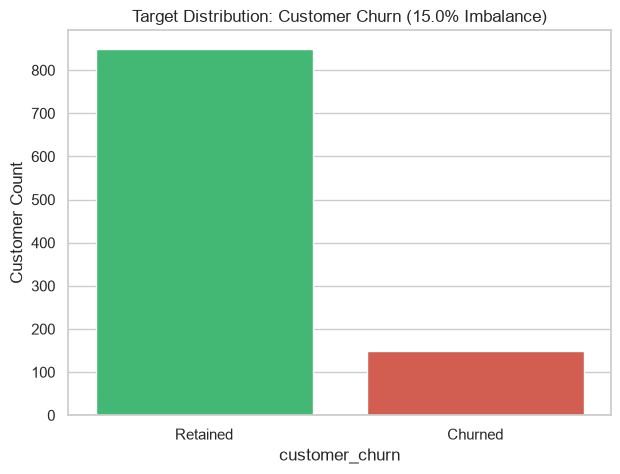

In [5]:
# Compute exact numerical class counts and proportions
counts = df['customer_churn'].value_counts()
props = df['customer_churn'].value_counts(normalize=True) * 100
print("--- Class Distribution Summary ---")
for cls in counts.index:
    print(f"{cls:10s}: {counts[cls]:4d} rows ({props[cls]:.2f}%)")

# Plot Target Distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x='customer_churn', palette=['#2ecc71', '#e74c3c'])
plt.title('Target Distribution: Customer Churn (15.0% Imbalance)')
plt.ylabel('Customer Count')
plt.show()

## 3. Subgroup Differences & Hypothesis Testing

Conducting non-parametric Mann-Whitney U tests for continuous features and Chi-Square contingency test for categorical features across `customer_churn`.

In [6]:
df['target'] = (df['customer_churn'] == 'Churned').astype(int)
num_cols = ['monthly_spend', 'number_of_store_visits_per_month', 'customer_satisfaction_score', 'number_of_complaints', 'discount_usage_rate']

print("--- Subgroup Statistical Tests (Mann-Whitney U) ---")
for col in num_cols:
    ret = df[df['target'] == 0][col]
    chu = df[df['target'] == 1][col]
    u_stat, p_val = stats.mannwhitneyu(ret, chu)
    print(f"{col:35s} | MWU Statistic: {u_stat:8.1f} | p-value: {p_val:.4e}")

# Chi-Square for membership_tier
contingency = pd.crosstab(df['membership_tier'], df['customer_churn'])
chi2, p_chi2, _, _ = stats.chi2_contingency(contingency)
print(f"\nmembership_tier Chi-Square Test | Chi2: {chi2:.2f} | p-value: {p_chi2:.4e}")

--- Subgroup Statistical Tests (Mann-Whitney U) ---
monthly_spend                       | MWU Statistic:  41395.0 | p-value: 7.1501e-12
number_of_store_visits_per_month    | MWU Statistic:  53630.0 | p-value: 1.9159e-03
customer_satisfaction_score         | MWU Statistic:  26072.0 | p-value: 7.1105e-31
number_of_complaints                | MWU Statistic:  96148.0 | p-value: 2.9569e-23
discount_usage_rate                 | MWU Statistic:  62722.0 | p-value: 7.5271e-01

membership_tier Chi-Square Test | Chi2: 21.10 | p-value: 2.6180e-05


## 4. Multicollinearity Assessment (VIF & Correlation)

Inspecting predictor-to-predictor correlations and Variance Inflation Factor (VIF) scores.

--- Variance Inflation Factor (VIF) --- 
                            feature       VIF
0                     monthly_spend  1.349092
1  number_of_store_visits_per_month  1.178036
2       customer_satisfaction_score  1.928314
3              number_of_complaints  1.778478
4               discount_usage_rate  1.116565


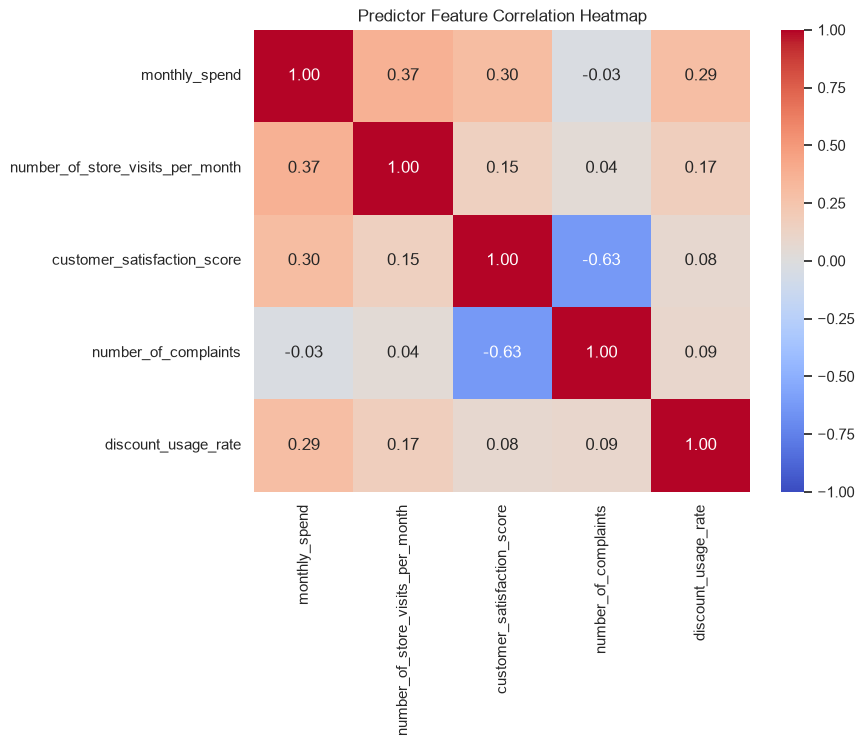

In [7]:
X_num = df[num_cols]
vif_df = pd.DataFrame()
vif_df["feature"] = num_cols
vif_df["VIF"] = [variance_inflation_factor(X_num.values, i) for i in range(X_num.shape[1])]
print("--- Variance Inflation Factor (VIF) --- ")
print(vif_df)

plt.figure(figsize=(8, 6))
sns.heatmap(X_num.corr(), annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Predictor Feature Correlation Heatmap')
plt.show()

## 5. Interaction Feature Engineering

Constructing domain-specific interaction features: `complaint_to_visit_ratio` and `spend_per_visit`.

In [8]:
df['complaint_to_visit_ratio'] = df['number_of_complaints'] / (df['number_of_store_visits_per_month'] + 1e-5)
df['spend_per_visit'] = df['monthly_spend'] / (df['number_of_store_visits_per_month'] + 1e-5)

print("--- Interaction Feature Hypothesis Tests ---")
for col in ['complaint_to_visit_ratio', 'spend_per_visit']:
    ret = df[df['target'] == 0][col]
    chu = df[df['target'] == 1][col]
    _, p_val = stats.mannwhitneyu(ret, chu)
    print(f"{col:30s} | MWU p-value: {p_val:.4e}")

--- Interaction Feature Hypothesis Tests ---
complaint_to_visit_ratio       | MWU p-value: 2.5129e-21
spend_per_visit                | MWU p-value: 2.8462e-01
